In [1]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler

house = pd.read_csv("House_Price_dataset.csv")
house

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.0
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,yes,no,yes,no,no,2.0,no,unfurnished
541,1767150,2400,3.0,1.0,1.0,no,no,no,no,no,0.0,no,semi-furnished
542,1750000,3620,2.0,1.0,1.0,yes,no,no,no,no,0.0,no,unfurnished
543,1750000,2910,3.0,1.0,1.0,no,no,no,no,no,0.0,no,furnished


In [2]:
le = LabelEncoder()

cols = ['mainroad', 'guestroom' , 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

for col in cols:
    house[col]=le.fit_transform(house[col])

In [3]:
size_mapping = {
    'furnished': 2,
    'semi-furnished': 1,
    'unfurnished': 0
}
house['furnishingstatus'] = house['furnishingstatus'].map(size_mapping)

In [4]:
house

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,2
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,2
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,2
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,0
541,1767150,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,1
542,1750000,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,0
543,1750000,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,2


In [5]:
house.mean(numeric_only=True)

price               4.766729e+06
area                5.150541e+03
bedrooms            2.961111e+00
bathrooms           1.285185e+00
stories             1.804788e+00
mainroad            8.587156e-01
guestroom           1.779817e-01
basement            3.504587e-01
hotwaterheating     4.587156e-02
airconditioning     3.155963e-01
parking             6.913124e-01
prefarea            2.348624e-01
furnishingstatus    9.302752e-01
dtype: float64

In [6]:
house.mode(numeric_only=True)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,3500000,6000.0,3.0,1.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,4200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
house.median(numeric_only=True)

price               4340000.0
area                   4600.0
bedrooms                  3.0
bathrooms                 1.0
stories                   2.0
mainroad                  1.0
guestroom                 0.0
basement                  0.0
hotwaterheating           0.0
airconditioning           0.0
parking                   0.0
prefarea                  0.0
furnishingstatus          1.0
dtype: float64

In [8]:
house.isnull().any()

price               False
area                False
bedrooms             True
bathrooms            True
stories              True
mainroad            False
guestroom           False
basement            False
hotwaterheating     False
airconditioning     False
parking              True
prefarea            False
furnishingstatus    False
dtype: bool

In [9]:
house.isnull().sum()

price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64

In [10]:
house["bedrooms"] = house["bedrooms"].fillna(house.bedrooms.median())
house["bathrooms"] = house["bathrooms"].fillna(house.bathrooms.median())
house["stories"] = house["stories"].fillna(house.stories.median())
house["parking"] = house["parking"].fillna(house.parking.median())
house

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2.0,1,2
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3.0,0,2
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2.0,1,1
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3.0,1,2
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2.0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,1,0,1,0,0,2.0,0,0
541,1767150,2400,3.0,1.0,1.0,0,0,0,0,0,0.0,0,1
542,1750000,3620,2.0,1.0,1.0,1,0,0,0,0,0.0,0,0
543,1750000,2910,3.0,1.0,1.0,0,0,0,0,0,0.0,0,2


In [11]:
house.isnull().any()

price               False
area                False
bedrooms            False
bathrooms           False
stories             False
mainroad            False
guestroom           False
basement            False
hotwaterheating     False
airconditioning     False
parking             False
prefarea            False
furnishingstatus    False
dtype: bool

In [12]:
from sklearn.model_selection import train_test_split

x1 = house['area']
y1 = house['price']
x_train1, x_test1, y_train1, y_test1 = train_test_split(x1, y1, train_size=0.8, random_state=42)

In [13]:
print("Train sizes:", x_train1.shape, y_train1.shape)
print("Test sizes:", x_test1.shape, y_test1.shape)

Train sizes: (436,) (436,)
Test sizes: (109,) (109,)


In [14]:
from sklearn import linear_model
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model1 = linear_model.LinearRegression()
model1.fit(x_train1.to_frame(), y_train1)

y_pred1 = model1.predict(x_test1.to_frame())

print(f" Coefficient: {model1.coef_}\n")
print(f" Intercept: {model1.intercept_}")

 Coefficient: [425.72984194]

 Intercept: 2512254.2639593435


In [15]:
#For single attribute linear regression model
mse = mean_squared_error(y_test1, y_pred1)
mae = mean_absolute_error(y_test1, y_pred1)
r2_square = r2_score(y_test1,y_pred1)

print(f"Mean Square Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"R Square Score: {r2_square}")

Mean Square Error: 3675286604768.185
Mean Absolute Error: 1474748.1337969352
R Square Score: 0.27287851871974644


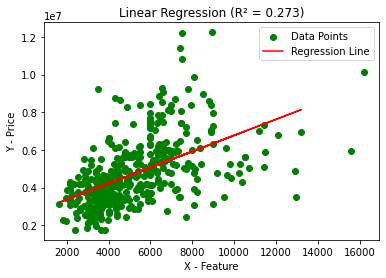

In [17]:
import matplotlib.pyplot as plt

plt.scatter(x_train1, y_train1, color='green', label='Data Points')

plt.plot(x_test1.to_numpy().flatten(),
         y_pred1.flatten() if hasattr(y_pred1, 'flatten') else y_pred1,
         color='red', label='Regression Line')

plt.title(f'Linear Regression (R² = {r2_square:.3f})')
plt.xlabel('X - Feature')
plt.ylabel('Y - Price')
plt.legend()

plt.show()

In [18]:
x2 = house.drop('price', axis=1)
y2 = house['price']
x_train2, x_test2, y_train2, y_test2 = train_test_split(x2, y2, train_size=0.8, random_state=42)

In [19]:
x_train2

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
46,6000,3.0,2.0,4.0,1,0,0,0,1,1.0,0,2
93,7200,3.0,2.0,1.0,1,0,1,0,1,3.0,0,1
335,3816,2.0,1.0,1.0,1,0,1,0,1,2.0,0,2
412,2610,3.0,1.0,2.0,1,0,1,0,0,0.0,1,0
471,3750,3.0,1.0,2.0,1,0,0,0,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
71,6000,4.0,2.0,4.0,1,0,0,0,1,0.0,0,0
106,5450,4.0,2.0,1.0,1,0,1,0,1,0.0,1,1
270,4500,3.0,2.0,3.0,1,0,0,1,0,1.0,0,2
435,4040,2.0,1.0,1.0,1,0,0,0,0,0.0,0,0


In [20]:
print("Train sizes:", x_train2.shape, y_train2.shape)
print("Test sizes:", x_test2.shape, y_test2.shape)

Train sizes: (436, 12) (436,)
Test sizes: (109, 12) (109,)


In [21]:
model2 = linear_model.LinearRegression()
model2.fit(x_train2, y_train2)

y_pred2 = model2.predict(x_test2)

print(f" Coefficient: {model2.coef_}\n")
print(f" Intercept: {model2.intercept_}")

 Coefficient: [2.38661524e+02 9.74306538e+04 1.05365483e+06 4.02429843e+05
 3.76507984e+05 2.32037535e+05 3.84678718e+05 6.87087166e+05
 7.96416107e+05 2.15766903e+05 6.20512488e+05 2.20617486e+05]

 Intercept: -137889.63652706426


In [22]:
mse = mean_squared_error(y_test2, y_pred2)
mae = mean_absolute_error(y_test2, y_pred2)
r2_square = r2_score(y_test2,y_pred2)

print(f"Mean Square Error: {mse}")
print(f"Mean Absolute Error: {mae}")g
print(f"R Square Score: {r2_square}")

Mean Square Error: 1762261595678.3098
Mean Absolute Error: 974800.4763575837
R Square Score: 0.6513528332210876


In [92]:
x3 = house.drop('price' , axis=1)
y3 = house['price']

poly = PolynomialFeatures(degree=2)

x_train3, x_test3, y_train3, y_test3 = train_test_split(x3,y3, train_size=0.8, random_state=42)

x_train3_poly = poly.fit_transform(x_train3)
x_test3_poly = poly.transform(x_test3)

model3 = linear_model.LinearRegression()
model3.fit(x_train3_poly,y_train3)

y_pred3 = model3.predict(x_test3_poly)

print(f" Coefficient: {model2.coef_}\n")
print(f" Intercept: {model2.intercept_}")

 Coefficient: [2.38661524e+02 9.74306538e+04 1.05365483e+06 4.02429843e+05
 3.76507984e+05 2.32037535e+05 3.84678718e+05 6.87087166e+05
 7.96416107e+05 2.15766903e+05 6.20512488e+05 2.20617486e+05]

 Intercept: -137889.6365270689


In [93]:
mse = mean_squared_error(y_test3, y_pred3)
mae = mean_absolute_error(y_test3, y_pred3)
r2_square = r2_score(y_test3, y_pred3)

print(f"Mean Square Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"R Square Score: {r2_square}")

Mean Square Error: 1761881279841.5505
Mean Absolute Error: 1008480.6960570427
R Square Score: 0.6514280751938416


In [94]:
def yes_no(prompt):
    return int(input(prompt).strip().lower() == 'yes')

house_attributes = {
    'area': int(input("Enter Area:")),
    'bedrooms': int(input("Enter Bedrooms:")),
    'bathrooms': int(input("Enter Bathrooms:")),
    'stories': int(input("Enter Stories:")),
    'mainroad': yes_no("Near mainroad(yes/no):"),
    'guestroom': yes_no("guestroom(yes/no):"),
    'basement': yes_no("Basement(yes/no):"),
    'hotwaterheating': yes_no("hotwaterheating(yes/no):"),
    'airconditioning': yes_no("airconditioning(yes/no):"),
    'parking': int(input("Enter Parking:")),
    'prefarea': yes_no("prefarea(yes/no):")
}

furnishing = input("furnishing(unfurnished/semi-furnished/furnished):").strip().lower()
house_attributes['furnishingstatus'] = {
    'unfurnished': 0,
    'semi-furnished': 1,
    'furnished': 2
}[furnishing]

print("House Features:\n")
for key,value in house_attributes.items():
    print(f"{key}: {value}\n")

user_frame = pd.DataFrame([house_attributes], columns=x3.columns)
user_frame_poly = poly.transform(user_frame)
y_pred = model3.predict(user_frame_poly)
print(f"Predicted Price: {y_pred}")

House Features:

area: 5634

bedrooms: 3

bathrooms: 2

stories: 2

mainroad: 1

guestroom: 1

basement: 0

hotwaterheating: 1

airconditioning: 1

parking: 2

prefarea: 1

furnishingstatus: 2

Predicted Price: [7707117.3193154]
